<a href="https://colab.research.google.com/github/fjessenia/papermobilejkn/blob/main/mobilejkn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install Sastrawi wordcloud imbalanced-learn matplotlib seaborn pandas numpy scikit-learn -q
import nltk
nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [9]:
# Cell 2: Load Dataset
import pandas as pd

# Ganti nama file sesuai file Kaggle kamu
df = pd.read_csv('kaggle_Mobile-JKN_Review.csv')
print(f"Total baris data awal: {len(df)}")
print("Kolom yang tersedia:", df.columns.tolist())
df.head(3)

Total baris data awal: 5000
Kolom yang tersedia: ['userName', 'score', 'at', 'content', 'sentiment_polarity', 'aspect_domain', 'slang_density_tier', 'cot_rationale', 'confidence_score']


,userName,score,at,content,sentiment_polarity,aspect_domain,slang_density_tier,cot_rationale,confidence_score
0,Pengguna Google,1,2026-10-17 22:00:54,aplikasi sering eror,negative,app_stability_crash,standard_formal,Ulasan dari peserta 'Pengguna Google' pada 202...,0.995
1,Pengguna Google,1,2026-10-17 21:15:13,aplikasi nya sangat aneh mendaftar nya juga su...,negative,registration_login_nik,heavy_slang,Ulasan dari peserta 'Pengguna Google' pada 202...,0.995
2,Pengguna Google,5,2026-10-17 20:00:25,mantap,positive,general_feedback,standard_formal,Ulasan dari peserta 'Pengguna Google' pada 202...,0.995


In [10]:
# Cell 3: Pembersihan Teks, Normalisasi Slang/Typo Khusus Mobile JKN, Simpan Angka & Filter Neutral
import pandas as pd
import re

# 1. Kamus Normalisasi Slang & Typo Terlengkap (Disesuaikan dengan Dataset Kaggle Mobile JKN)
slang_dict = {
    # 1. Kata Negasi (PENTING: Jangan dihapus agar makna negatif/mixed terjaga)
    'gk': 'tidak', 'gak': 'tidak', 'ga': 'tidak', 'tdk': 'tidak', 'nggak': 'tidak', 'g':'tidak','gx':'tidak',
    'ngak': 'tidak', 'gabisa': 'tidak bisa', 'gakbisa': 'tidak bisa',
    'jgn': 'jangan', 'bkn': 'bukan',

    # 2. Singkatan Kata Hubung & Kata Ganti
    'yg': 'yang', 'tp': 'tapi', 'tpi': 'tapi', 'lg': 'lagi', 'lgi': 'lagi',
    'jd': 'jadi', 'jdi': 'jadi', 'sy': 'saya', 'sya': 'saya', 'dgn': 'dengan',
    'org': 'orang', 'gt': 'gitu', 'gth': 'gitu', 'dr': 'dari', 'sm': 'sama',
    'sma': 'sama', 'krn': 'karena', 'karna': 'karena', 'krna': 'karena',
    'utk': 'untuk', 'bwt': 'buat', 'gmn': 'gimana', 'knp': 'kenapa',
    'klo': 'kalau', 'klau': 'kalau', 'trus': 'terus', 'tros': 'terus',
    'dpt': 'dapat', 'mgkn': 'mungkin', 'kpn': 'kapan',

    # 3. Kata Gaul / Typo Aplikasi
    'bgus': 'bagus', 'bgt': 'banget', 'bgtu': 'begitu', 'dftr': 'daftar',
    'antri': 'antrean', 'antren': 'antrean', 'antrian': 'antrean',
    'lemot': 'lambat', 'eror': 'error', 'erorr': 'error', 'errorr': 'error',
    'pake': 'pakai', 'pakek': 'pakai', 'pakae': 'pakai', 'mulu': 'selalu',
    'blm': 'belum', 'sdh': 'sudah', 'udh': 'sudah', 'udah': 'sudah',
    'aplikasiny': 'aplikasinya', 'app': 'aplikasi', 'apk': 'aplikasi',
    'stres': 'stres', 'stress': 'stres', 'blng': 'bilang', 'plis': 'tolong', 'pliss': 'tolong'
}

def clean_and_normalize(text):
    if not isinstance(text, str):
        return ""

    # a. Hapus URL / Link Web
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # b. Hapus Emoji, Mojibake (ðŸ‘ dll), dan Karakter Non-ASCII
    text = text.encode('ascii', 'ignore').decode('ascii')

    # c. Hapus Simbol & Tanda Baca (TETAP SIMPAN Huruf A-Z dan Angka 0-9)
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)

    # d. Case Folding (Huruf kecil semua) & Merapikan Spasi
    text = re.sub(r'\s+', ' ', text).strip().lower()

    # e. Normalisasi Slang / Typo Kata
    words = text.split()
    normalized_words = [slang_dict.get(w, w) for w in words]
    return " ".join(normalized_words)

# Terapkan pembersihan dan normalisasi ke kolom ulasan mentah
df['content_clean'] = df['content'].apply(clean_and_normalize)

# Hapus ulasan yang kosong/kurang dari 4 karakter setelah dibersihkan
df_clean = df[df['content_clean'].str.len() > 3].reset_index(drop=True)

# Filter Out / Buang Ulasan Neutral otomatis
if 'sentiment_polarity' in df_clean.columns:
    df_clean = df_clean[df_clean['sentiment_polarity'].astype(str).str.lower() != 'neutral'].reset_index(drop=True)

# Export file hasil pembersihan untuk bahan Anotasi Excel Annotator 1 & 2
df_clean.to_csv('data_for_annotation.csv', index=False)

print(" Pembersihan & Normalisasi Data Berhasil!")
print(f"Total data siap di-annotate: {len(df_clean)} baris.")
print("File berhasil diexport ke 'data_for_annotation.csv'. Silakan download untuk di-annotate di Excel!")

 Pembersihan & Normalisasi Data Berhasil!
Total data siap di-annotate: 4710 baris.
File berhasil diexport ke 'data_for_annotation.csv'. Silakan download untuk di-annotate di Excel!


In [4]:
# Cell 4: Read Final Annotated Data, Cohen's Kappa Check & Ground Truth Filtering (Huruf Kecil)
import pandas as pd
from sklearn.metrics import cohen_kappa_score

# 1. Read dataset yang sudah di-annotate dari Excel
df_annotated = pd.read_csv('dataset_annotated_final.csv')

# Ubah semua teks label ke huruf kecil (lowercase) & bersihkan spasi liar
df_annotated['label_annotator1'] = df_annotated['label_annotator1'].astype(str).str.lower().str.strip()
if 'label_annotator2' in df_annotated.columns:
    df_annotated['label_annotator2'] = df_annotated['label_annotator2'].astype(str).str.lower().str.strip()

# 2. Hitung Skor Cohen's Kappa pada sampel data yang diisi oleh KEDUA annotator
if 'label_annotator2' in df_annotated.columns:
    df_sample = df_annotated.dropna(subset=['label_annotator1', 'label_annotator2'])
    df_sample = df_sample[df_sample['label_annotator1'].isin(['positive', 'negative', 'mixed'])]
    df_sample = df_sample[df_sample['label_annotator2'].isin(['positive', 'negative', 'mixed'])]

    kappa = cohen_kappa_score(df_sample['label_annotator1'], df_sample['label_annotator2'])
    print(f" Skor Inter-Rater Reliability (Cohen's Kappa): {kappa:.4f}")

    if kappa >= 0.80:
        print(" Status: Kesepakatan SANGAT TINGGI (Almost Perfect Agreement, Valid untuk Training Model!)")
    elif kappa >= 0.60:
        print(" Status: Kesepakatan CUKUP TINGGI (Substantial Agreement)")
    else:
        print(" Status: Kesepakatan Sedang/Rendah. Diskusikan baris data yang mismatch.")

# 3. Ambil data Annotator 1 & FILTER HANYA 3 KELAS TARGET MURNI (positive, negative, mixed)
# Label 'neutral', 'drop', atau 'nan' akan otomatis dibuang/ditakeout dari model!
df_final = df_annotated[df_annotated['label_annotator1'].isin(['positive', 'negative', 'mixed'])].reset_index(drop=True)

print("\n==================================================")
print(f"Total data awal di Excel : {len(df_annotated)} baris")
print(f"Total data final (3 Kelas): {len(df_final)} baris")
print("==================================================")
print("\nDistribusi 3 Kelas Target Final (Annotator 1 Ground Truth):")
print(df_final['label_annotator1'].value_counts())

 Skor Inter-Rater Reliability (Cohen's Kappa): 0.9417
 Status: Kesepakatan SANGAT TINGGI (Almost Perfect Agreement, Valid untuk Training Model!)

Total data awal di Excel : 4710 baris
Total data final (3 Kelas): 4688 baris

Distribusi 3 Kelas Target Final (Annotator 1 Ground Truth):
label_annotator1
positive    2388
negative    2220
mixed         80
Name: count, dtype: int64


In [5]:
# Cell 5: Stopwords Removal (Mengecualikan Negasi) & Stemming Sastrawi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from nltk.corpus import stopwords
import nltk

nltk.download('stopwords')

# 1. Ambil daftar stopword Bahasa Indonesia standar NLTK
indonesian_stopwords = set(stopwords.words('indonesian'))

# 2. Kecualikan kata negasi (PENTING: Kata-kata ini JANGAN dihapus agar sentimen negatif & mixed tidak hancur)
negation_words = {'tidak', 'bukan', 'jangan', 'kurang', 'belum'}
custom_stopwords = indonesian_stopwords - negation_words

# 3. Tambahkan kata benda/sebutan aplikasi yang terlalu sering muncul (optional)
additional_words = {'aplikasi', 'jkn', 'mobile', 'bpjs', 'nya'}
all_stopwords = custom_stopwords.union(additional_words)

# 4. Inisialisasi Stemmer Sastrawi
factory = StemmerFactory()
stemmer = factory.create_stemmer()

def preprocess_text(text):
    if not isinstance(text, str):
        return ""
    tokens = text.split()
    # Menghapus stopword (kecuali kata negasi) dan kata pendek <= 2 huruf
    tokens = [w for w in tokens if w not in all_stopwords and len(w) > 2]
    text_clean = " ".join(tokens)
    # Ubah ke kata dasar dengan Sastrawi
    return stemmer.stem(text_clean)

print("Memproses Stemming Sastrawi (mohon tunggu 2-4 menit)...")
df_final['stemmed_text'] = df_final['content_clean'].apply(preprocess_text)
print(" Preprocessing & Stemming Selesai!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Memproses Stemming Sastrawi (mohon tunggu 2-4 menit)...
 Preprocessing & Stemming Selesai!


In [6]:
# Cell 6: N-Gram TF-IDF & Stratified Train-Test Split (80:20)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF (1,2) Unigram + Bigram
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X = tfidf.fit_transform(df_final['stemmed_text'])
y = df_final['label_annotator1']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f" Bentuk Matriks TF-IDF (Data Latih: {X_train.shape[0]}, Data Uji: {X_test.shape[0]})")

 Bentuk Matriks TF-IDF (Data Latih: 3750, Data Uji: 938)


In [7]:
# Cell 7: Pelatihan 4 Model ML Benchmark & Imbalance Handling
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score
from imblearn.over_sampling import SMOTE

# Terapkan SMOTE khusus training set untuk menangani class imbalance
smote = SMOTE(random_state=42, k_neighbors=1)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

models = {
    "Multinomial Naïve Bayes (+ SMOTE)": (MultinomialNB(), X_train_smote, y_train_smote),
    "Linear SVM (Class Weighted)": (LinearSVC(class_weight='balanced', random_state=42), X_train, y_train),
    "Logistic Regression (Class Weighted)": (LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42), X_train, y_train),
    "Random Forest (+ SMOTE)": (RandomForestClassifier(n_estimators=100, random_state=42), X_train_smote, y_train_smote)
}

results = {}
print("================ HASIL EVALUASI BENCHMARK MODEL ================\n")
for name, (model, X_tr, y_tr) in models.items():
    model.fit(X_tr, y_tr)
    preds = model.predict(X_test)

    acc = accuracy_score(y_test, preds)
    macro_f1 = f1_score(y_test, preds, average='macro')
    weighted_f1 = f1_score(y_test, preds, average='weighted')

    results[name] = {"Accuracy": acc, "Macro F1": macro_f1, "Weighted F1": weighted_f1, "Predictions": preds}

    print(f"--- {name} ---")
    print(f"Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f} | Weighted F1: {weighted_f1:.4f}")
    print(classification_report(y_test, preds))
    print("=" * 65 + "\n")

================ HASIL EVALUASI BENCHMARK MODEL ================

--- Multinomial Naïve Bayes (+ SMOTE) ---
Accuracy: 0.8529 | Macro F1: 0.6296 | Weighted F1: 0.9003
              precision    recall  f1-score   support

       mixed       0.03      0.25      0.06        16
    negative       0.96      0.88      0.92       444
    positive       0.99      0.85      0.91       478

    accuracy                           0.85       938
   macro avg       0.66      0.66      0.63       938
weighted avg       0.96      0.85      0.90       938


--- Linear SVM (Class Weighted) ---
Accuracy: 0.9616 | Macro F1: 0.7412 | Weighted F1: 0.9576
              precision    recall  f1-score   support

       mixed       0.60      0.19      0.29        16
    negative       0.96      0.96      0.96       444
    positive       0.96      0.99      0.98       478

    accuracy                           0.96       938
   macro avg       0.84      0.71      0.74       938
weighted avg       0.96      0.9

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


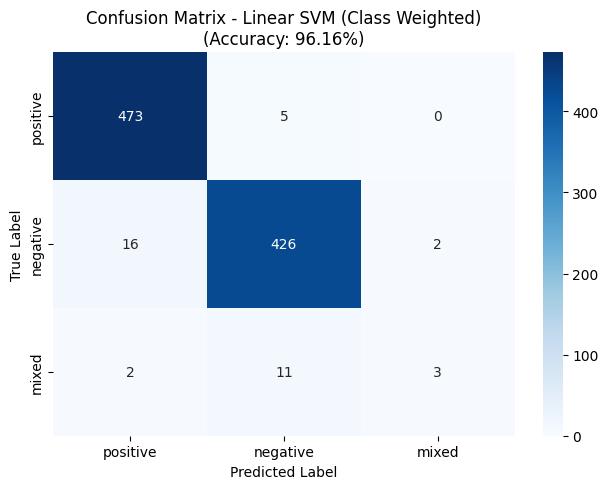

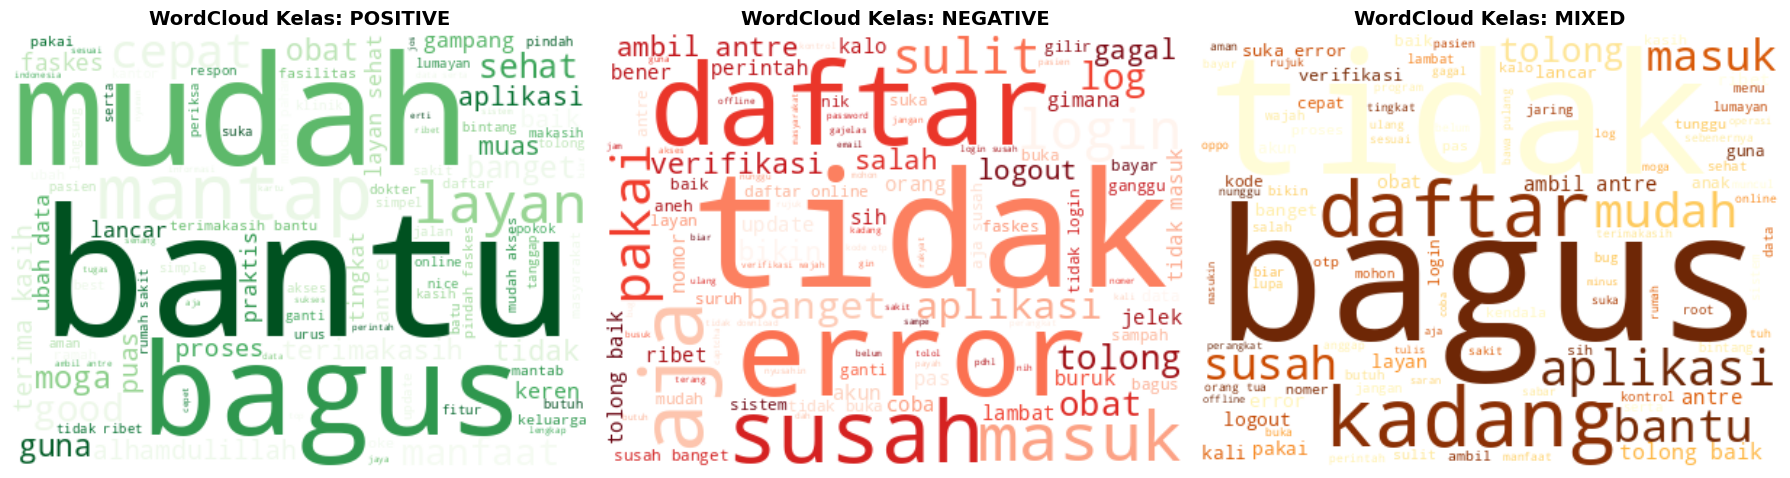


 Gambar 'confusion_matrix_best.png' & 'wordcloud_sentiments.png' berhasil disave!
Silakan unduh dari folder file Colab sebelah kiri 📁.


In [8]:
# Cell 8: Visualisasi Confusion Matrix Model Terbaik (Linear SVM) & WordCloud 3 Kelas
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from wordcloud import WordCloud

# 1. Plot Confusion Matrix Model Terbaik (Linear SVM)
best_model_name = "Linear SVM (Class Weighted)"
preds_best = results[best_model_name]["Predictions"]
cm = confusion_matrix(y_test, preds_best, labels=['positive', 'negative', 'mixed'])

plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['positive', 'negative', 'mixed'],
            yticklabels=['positive', 'negative', 'mixed'])
plt.title(f'Confusion Matrix - {best_model_name}\n(Accuracy: {results[best_model_name]["Accuracy"]*100:.2f}%)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('confusion_matrix_best.png', dpi=300)
plt.show()

# 2. Plot WordCloud 3 Kelas (positive, negative, mixed)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sentiments = ['positive', 'negative', 'mixed']
colors = ['Greens', 'Reds', 'YlOrBr']

for i, sent in enumerate(sentiments):
    text_data = ' '.join(df_final[df_final['label_annotator1'] == sent]['stemmed_text'])
    wc = WordCloud(width=400, height=300, background_color='white', colormap=colors[i], max_words=100).generate(text_data)
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].set_title(f'WordCloud Kelas: {sent.upper()}', fontsize=14, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('wordcloud_sentiments.png', dpi=300)
plt.show()

print("\n Gambar 'confusion_matrix_best.png' & 'wordcloud_sentiments.png' berhasil disave!")
print("Silakan unduh dari folder file Colab sebelah kiri 📁.")